## Repeated Commuting Driving Behavior (Flag 10)

### Dataset Overview
A WorldTrace-style dataset of 120 commute trajectories from 12 users between Northgate Residential District and Harbor Business District. It provides trip-level route choice, direction, start and arrival times, distance and speed, plus linked timestamped trajectory points.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Summarize the commuting driving behavior of users from the supplied repeated travel trajectories.

Role: Mobility behavior analyst


Category: Multi-user commuting route choice and convergence

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: For users repeatedly commuting between the same two districts, how many retain one corridor and how many ever use an alternative?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

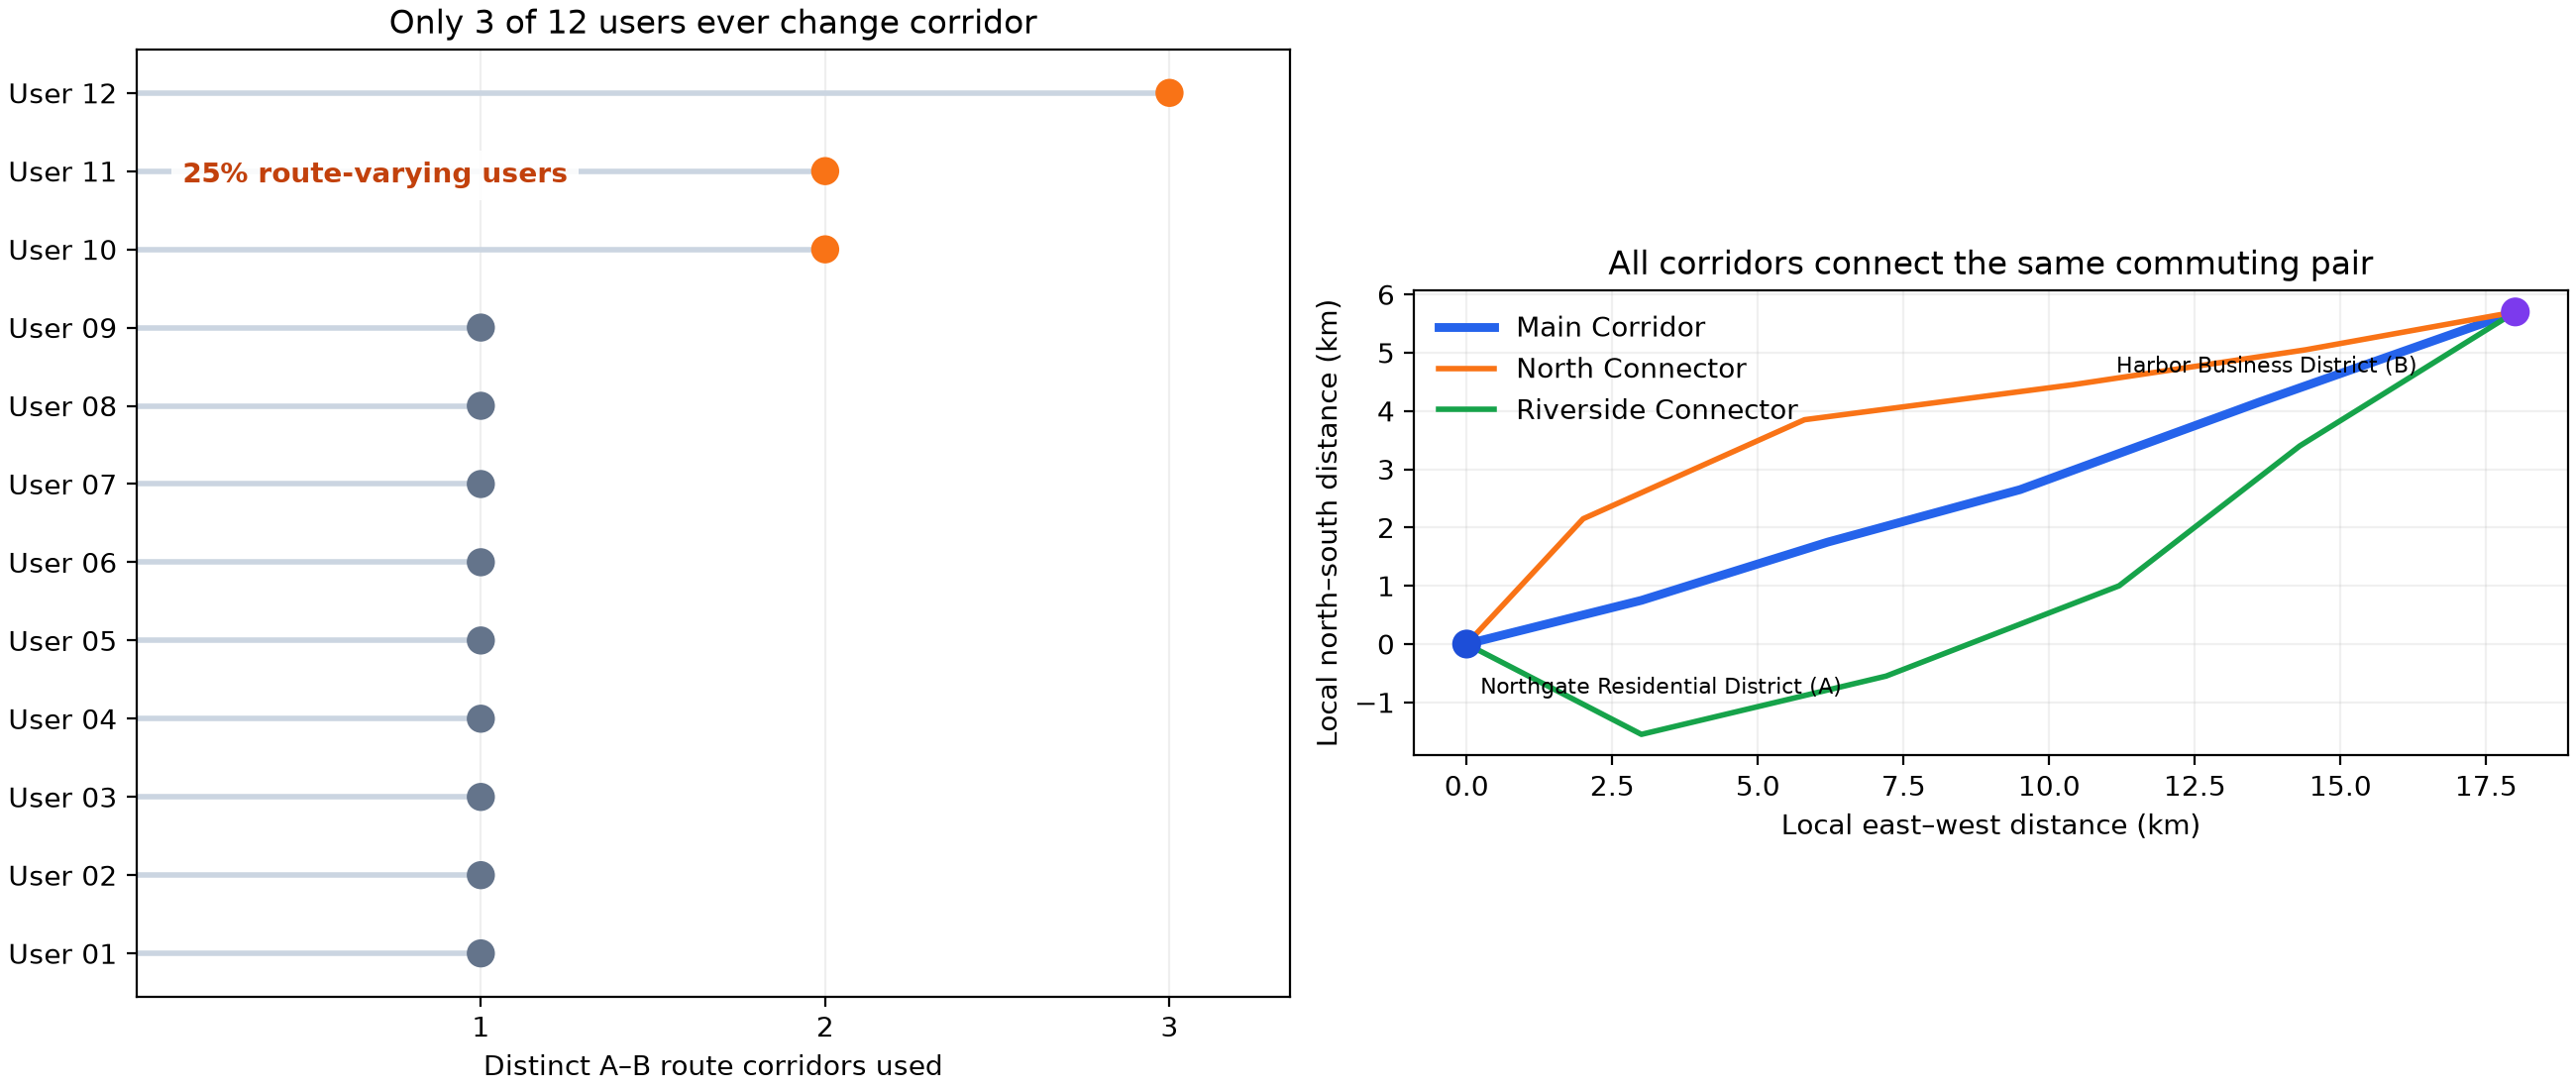

In [ ]:
summary = df.groupby('user_id').route_name.nunique(); print(summary); print((summary > 1).mean())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/user_route_consistency.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "user_route_diversity",
  "insight": "Although users repeatedly commute between Northgate Residential District and Harbor Business District in both directions, most retain one fixed route; only 25% ever switch between corridors for the same origin–destination pair.",
  "insight_value": {
    "users": 12,
    "route_varying_users": 3,
    "route_varying_share": 0.25
  },
  "plot": {
    "plot_type": "user_route_diversity_and_corridor_map",
    "title": "User-Level Route Consistency",
    "file": "visualizations/user_route_consistency.png",
    "description": "The left panel counts distinct corridors used per user; the right panel shows the three A–B corridor geometries."
  },
  "question": "For users repeatedly commuting between the same two districts, how many retain one corridor and how many ever use an alternative?",
  "code": "summary = df.groupby('user_id').route_name.nunique(); print(summary); print((summary > 1).mean())",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 2**: Which corridor is used by most supplied trips, and within what full time intervals do users travel on that corridor?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

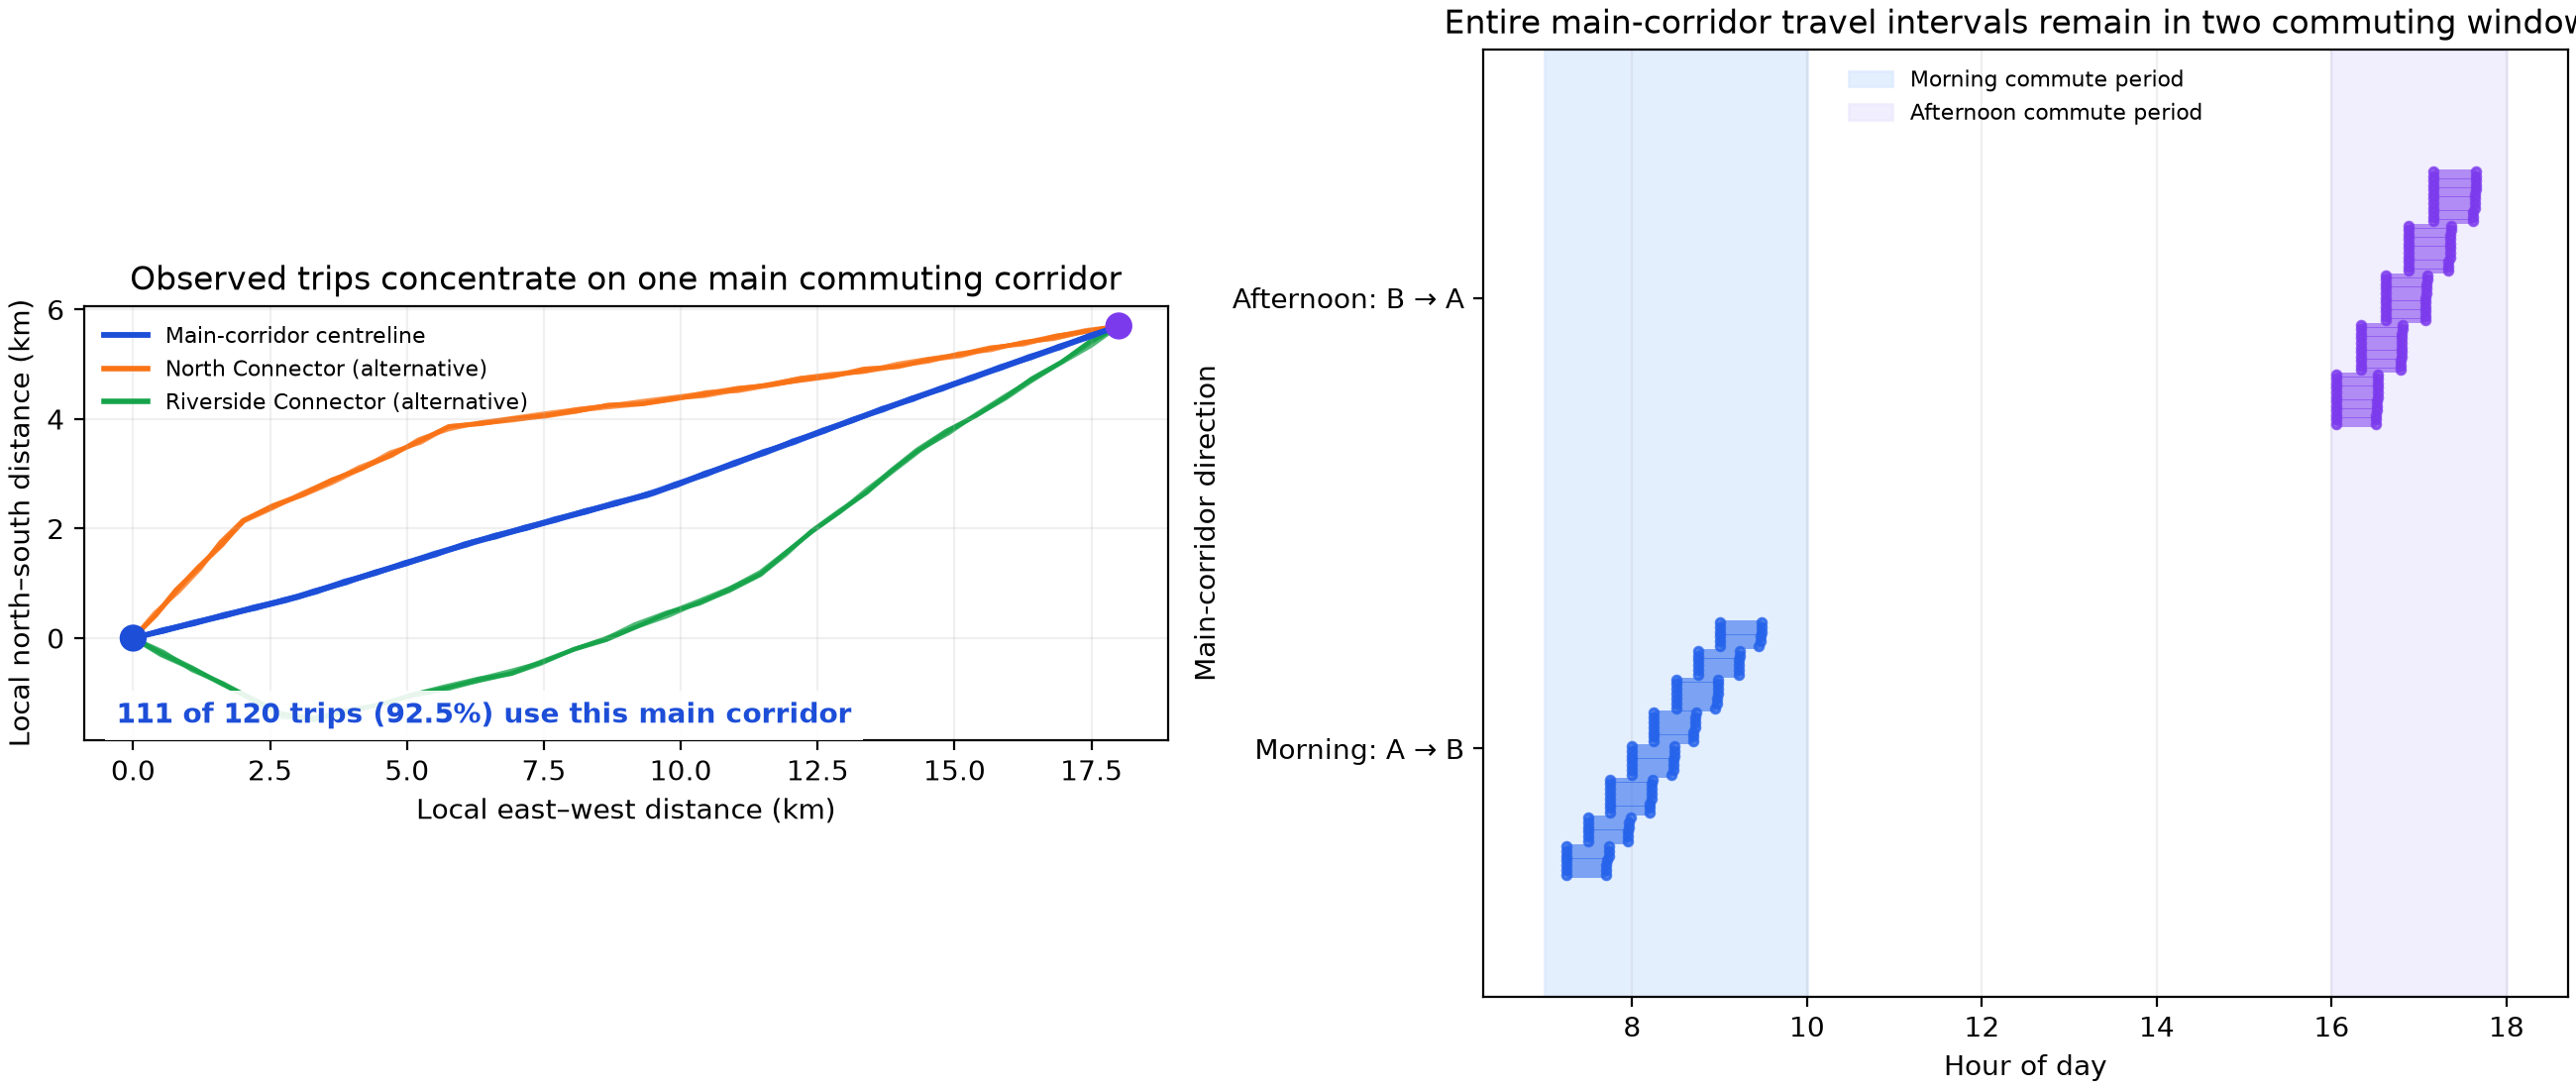

In [ ]:
d = df[df.is_main_corridor].copy(); d['departure_time']=pd.to_datetime(d.departure_time); d['arrival_time']=pd.to_datetime(d.arrival_time); print(d[['departure_time','arrival_time']].describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/main_corridor_and_commute_times.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "main_corridor_time_concentration",
  "insight": "Despite user-level route variation, a clear main corridor is used by most trips, and the full time intervals spent on it consistently remain within the 07:00–10:00 morning and 16:00–18:00 afternoon commuting periods.",
  "insight_value": {
    "main_corridor_trips": 111,
    "all_trips": 120,
    "main_corridor_share": 0.925
  },
  "plot": {
    "plot_type": "main_corridor_map_and_travel_interval_timeline",
    "title": "Main Corridor and Commuting Periods",
    "file": "visualizations/main_corridor_and_commute_times.png",
    "description": "Main-corridor geometries are overlaid with the full start-to-arrival intervals of every main-corridor trip in the two commuting windows."
  },
  "question": "Which corridor is used by most supplied trips, and within what full time intervals do users travel on that corridor?",
  "code": "d = df[df.is_main_corridor].copy(); d['departure_time']=pd.to_datetime(d.departure_time); d['arrival_time']=pd.to_datetime(d.arrival_time); print(d[['departure_time','arrival_time']].describe())",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id",
    "trajectory_timestamp"
  ]
}

### **Question 3**: For users who tried alternative corridors, how does alternative-route use change as they repeat the commute?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

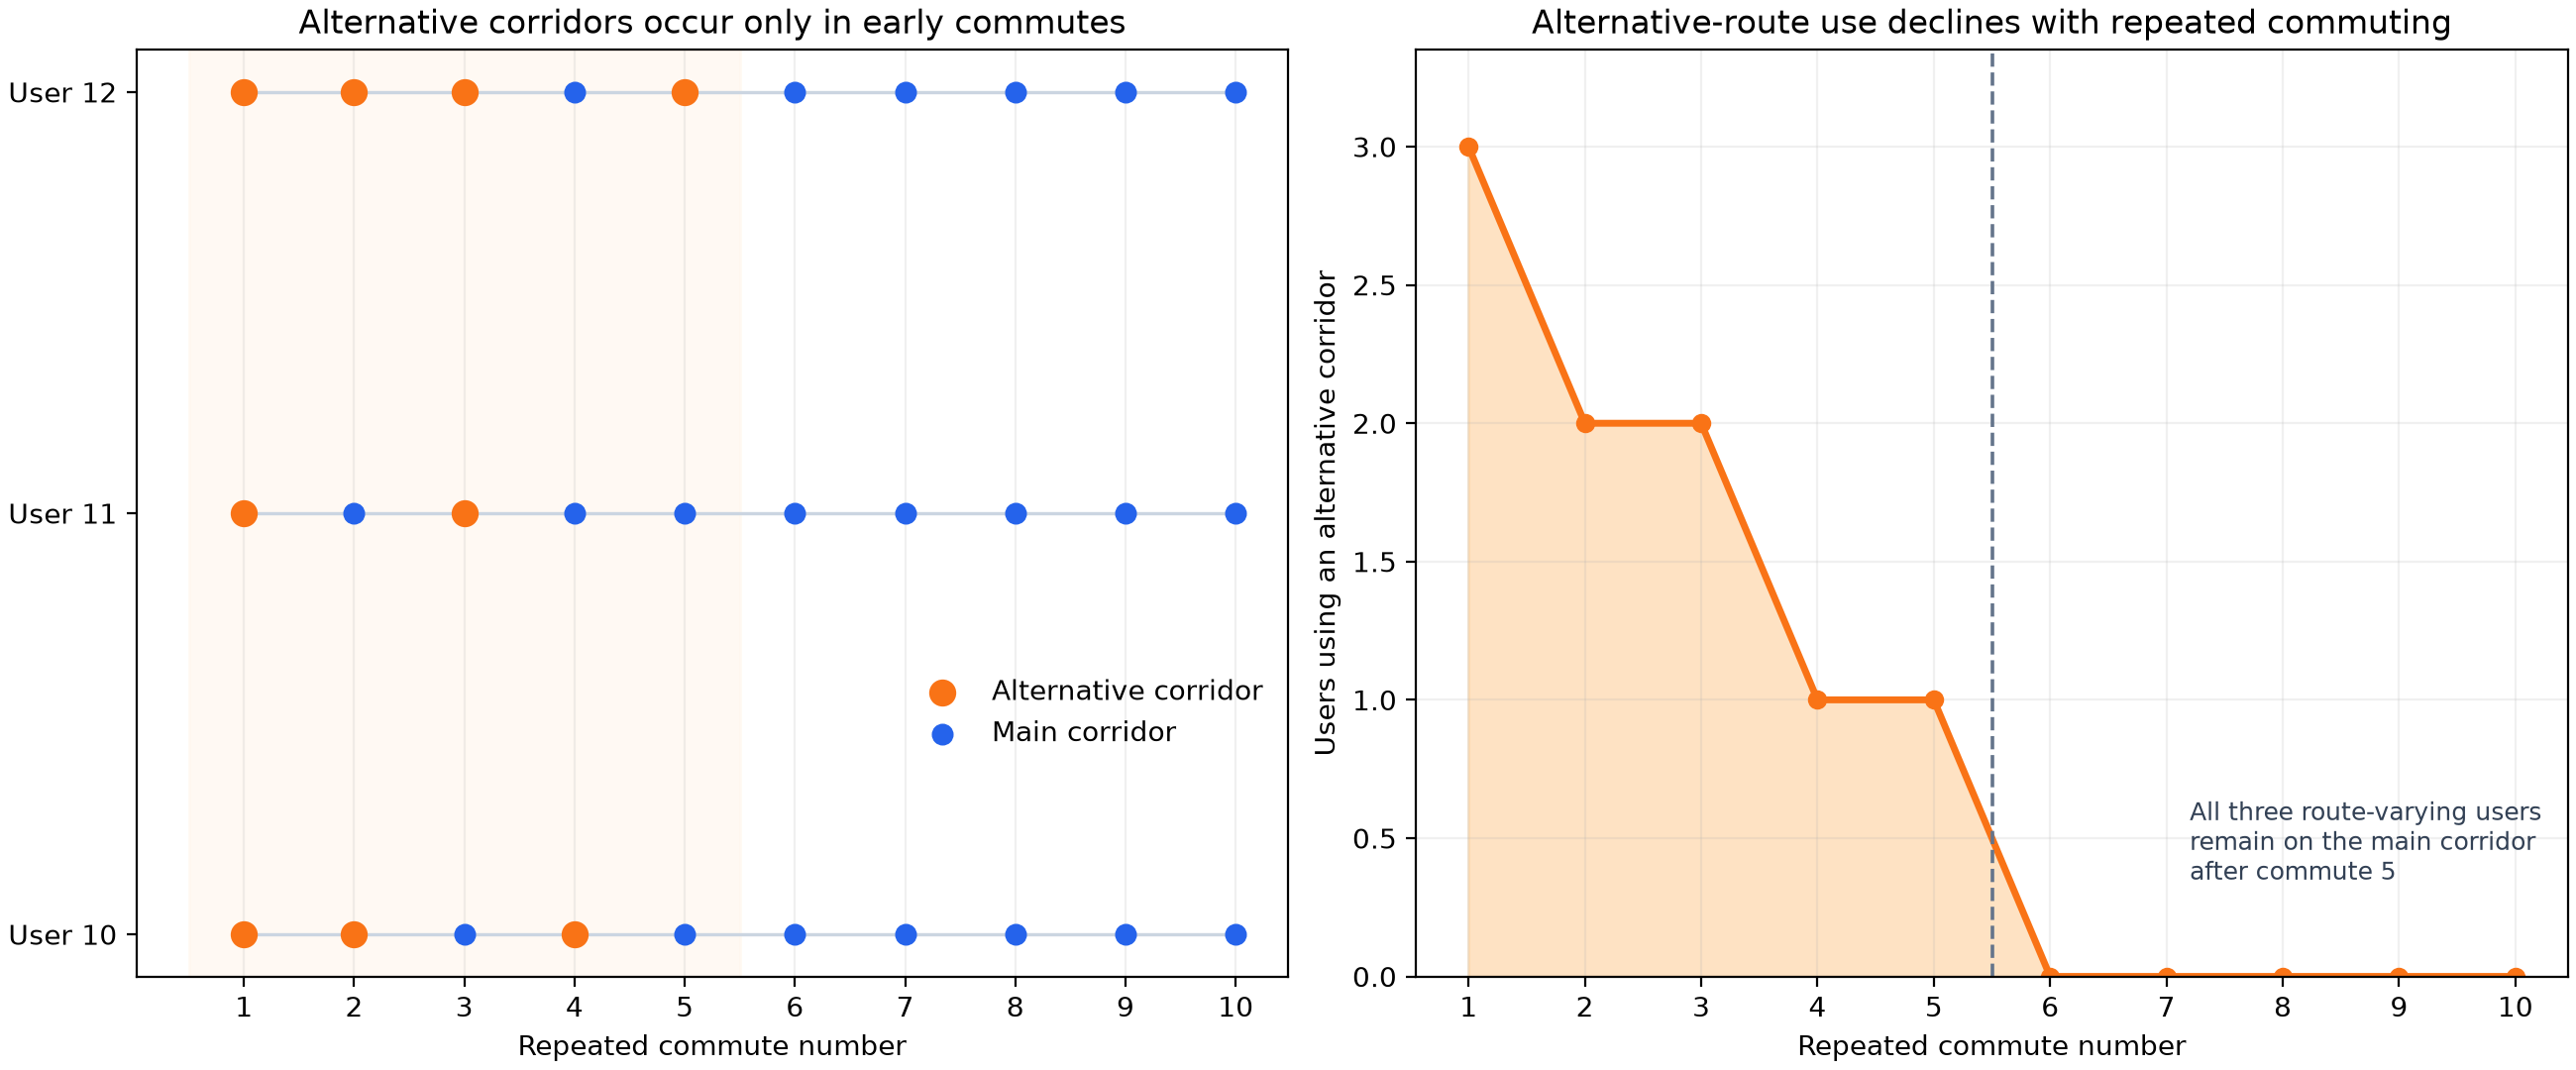

In [ ]:
d = df[df.user_id.isin(['commuter_10','commuter_11','commuter_12'])].copy(); d['alternative'] = ~d.is_main_corridor; print(d.groupby('commute_number').alternative.sum())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/route_convergence_over_repeated_commutes.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "route_adaptation_over_repetitions",
  "insight": "Among the 25% of users who try alternatives, alternative-route use declines over repeated commutes; after the fifth commute, all of them use the main commuting corridor.",
  "insight_value": {
    "route_varying_users": [
      "commuter_10",
      "commuter_11",
      "commuter_12"
    ],
    "alternative_users_after_commute_5": 0
  },
  "plot": {
    "plot_type": "per_user_route_sequence_and_alternative_count",
    "title": "Route Convergence over Repeated Commutes",
    "file": "visualizations/route_convergence_over_repeated_commutes.png",
    "description": "The left panel traces each route-varying user’s choices; the right panel aggregates alternative-corridor use by commute number."
  },
  "question": "For users who tried alternative corridors, how does alternative-route use change as they repeat the commute?",
  "code": "d = df[df.user_id.isin(['commuter_10','commuter_11','commuter_12'])].copy(); d['alternative'] = ~d.is_main_corridor; print(d.groupby('commute_number').alternative.sum())",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position"
  ]
}

### Summary of Findings (Flag 10)

Most users repeatedly drive the same corridor between the two commuting districts, while only three users initially explore alternatives. The main corridor dominates the supplied trips, with each complete traversal remaining in the morning or afternoon commuting windows. The users who explored alternatives converge to the main corridor after several repeated commutes.